# Implementing K-means

Using the Iris dataset and standardized features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

## Load the dataset

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

print(X.head())
print("Dataset shape:", X.shape)
print(X.describe())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Dataset shape: (150, 4)
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   


## Visualize the Data
```
What does this do?
- plt.subplots() creates a plotting area.
- ax.scatter() creates a scatter plot.
- The first argument represents the X-axis.
- The second argument represents the Y-axis.
- set_xlabel() and set_ylabel() label the axes.
- set_title() gives the graph a title.
- plt.show() displays the graph.
```

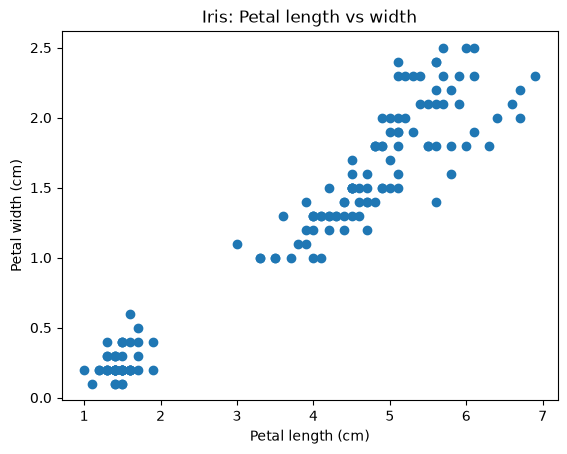

In [3]:
fig, ax = plt.subplots()

ax.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"]
)

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Iris: Petal length vs width")

plt.show()

##### Sepal Length against Sepal Width:

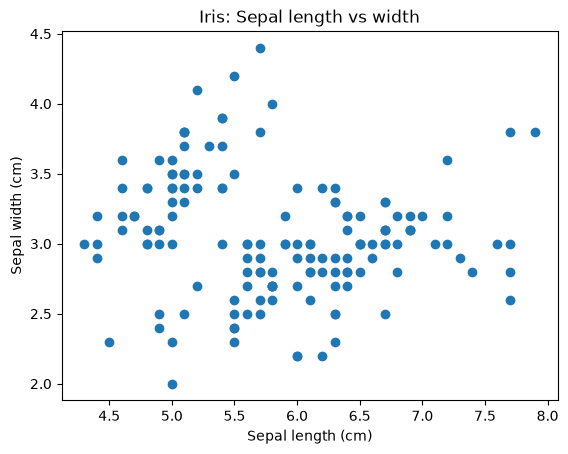

In [4]:
fig, ax = plt.subplots()

ax.scatter(
    X["sepal length (cm)"],
    X["sepal width (cm)"]
)

ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Sepal width (cm)")
ax.set_title("Iris: Sepal length vs width")

plt.show()

## Standardize the Features

This is a very important preprocessing step.

Different features may have different scales. Features with larger numerical values or variation can disproportionately influence distance calculations.

Standardization converts features to a comparable scale.

The formula is:
$$
z=\frac{x-\mu}{\sigma}
$$

Where:
- $(x)$ = Original value.
- $(\mu)$ = Mean.
- $(\sigma)$ = Standard deviation.
- $(z)$ = Standardized value.

After standardization, each feature has approximately:
- Mean = 0.
- Standard deviation = 1.

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original data:")
print(X.iloc[:2].values)

print("\nStandardized data:")
print(X_scaled[:2])

Original data:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]

Standardized data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]]


## Fit K-means with three clusters

In [6]:
kmeans = KMeans(
    n_clusters=3,
    n_init="auto",
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster labels:")
print(kmeans_labels[:10])

print("Inertia:")
print(kmeans.inertia_)

Cluster labels:
[1 2 2 2 1 1 1 1 2 2]
Inertia:
191.02473685317972


**Understanding the parameters:**
| Parameter | Explanation |
|---|---|
| `n_clusters=3` | Number of clusters to create |
| `n_init="auto"` | Controls the number of initializations |
| `random_state=42` | Makes the initialization reproducible |
| `fit_predict()` | Trains the algorithm and returns cluster labels |
| `inertia_` | Returns the within-cluster sum of squares |

**Why use `random_state=42`?**

K-means uses initial cluster centres that can vary between runs.

Setting a random state helps produce reproducible results.

## Visualize the Clusters

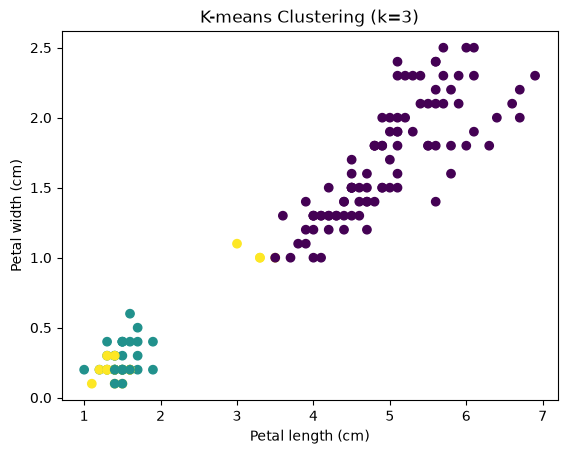

In [7]:
fig, ax = plt.subplots()

ax.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"],
    c=kmeans_labels
)

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("K-means Clustering (k=3)")

plt.show()

## Experiment with different values of K
```
- K = 2.
- K = 3.
- K = 4.
```

Why?

Because the number of clusters affects the grouping structure.

In [8]:
for k in [2, 3, 4]:

    kmeans = KMeans(
        n_clusters=k,
        n_init="auto",
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    print(
        f"K = {k}, "
        f"Inertia = {kmeans.inertia_:.2f}"
    )

K = 2, Inertia = 222.36
K = 3, Inertia = 191.02
K = 4, Inertia = 114.35


**Interpretation**
```
- K = 2 produces two groups.
- K = 3 produces three groups.
- K = 4 produces four groups.
```

A higher number of clusters usually results in lower inertia, but it may create unnecessary or less meaningful groups.

We therefore need an evaluation technique to help select K.

## Choosing the optimal number of clusters
#### Elbow Method

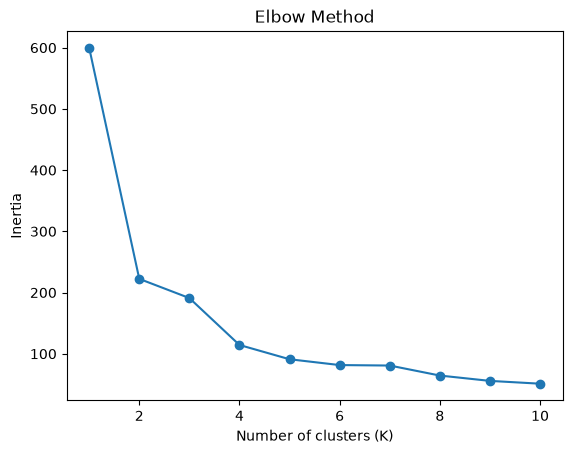

In [9]:
inertias = []

K_values = range(1, 11)

for k in K_values:

    model = KMeans(
        n_clusters=k,
        n_init="auto",
        random_state=42
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

plt.plot(
    K_values,
    inertias,
    marker="o"
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

**Interpretation**: Look for the point where adding more clusters produces a much smaller improvement in inertia.

The elbow is a visual guide, not a guaranteed mathematically optimal solution.